In [1]:
# ============================================================
# Predicción de abandono de clientes — IBM Telco Customer Churn
# Versión didáctica: comparación simple de cinco modelos
# Documentación completa: DOCUMENTACION.md
# Kernel: Python 3.15 (Telco Churn)
# ============================================================

# 1. Importaciones y configuración
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Semilla: permite repetir siempre la misma división de datos
RANDOM_STATE = 42
DATA_PATH = Path("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
TARGET = "Churn"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

print(f"Python      : {sys.version.split()[0]}")
print(f"pandas      : {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"XGBoost     : {xgboost.__version__}")

Python      : 3.15.2
pandas      : 3.1.1
scikit-learn: 1.9.1
XGBoost     : 3.4.1


In [2]:
# 2. Cargar los datos
df = pd.read_csv(DATA_PATH)

print(f"Clientes: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Clientes: 7,043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 3. Revisar la variable objetivo
# Churn = Yes significa que el cliente abandonó.
conteo = df[TARGET].value_counts().rename(index={"No": "No abandona", "Yes": "Abandona"})
tabla_objetivo = pd.DataFrame(
    {
        "clientes": conteo,
        "porcentaje": (conteo / len(df) * 100).round(2),
    }
)
print(tabla_objetivo.to_string())

# TotalCharges viene como texto porque 11 registros están vacíos.
no_numericos = pd.to_numeric(df["TotalCharges"], errors="coerce").isna()
print(f"\nTotalCharges vacío: {no_numericos.sum()} registros")
print(df.loc[no_numericos, ["tenure", "TotalCharges"]].to_string(index=False))

             clientes  porcentaje
Churn                            
No abandona      5174       73.46
Abandona         1869       26.54

TotalCharges vacío: 11 registros
 tenure TotalCharges
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             
      0             


In [4]:
# 4. Limpiar los datos
# - TotalCharges: de texto a número.
# - Churn: de Yes/No a 1/0, porque los modelos necesitan números.
df = df.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df[TARGET] = df[TARGET].map({"No": 0, "Yes": 1})

# Los 11 vacíos son clientes con antigüedad 0 (aún no tienen facturación).
# Si apareciera otro caso, hay que revisarlo antes de continuar.
faltantes = df["TotalCharges"].isna()
assert (df.loc[faltantes, "tenure"] == 0).all(), "Revisar TotalCharges faltante"

print(f"TotalCharges vacío: {faltantes.sum()} casos, todos con antigüedad 0")
print(f"Tasa de abandono: {df[TARGET].mean():.2%}")

TotalCharges vacío: 11 casos, todos con antigüedad 0
Tasa de abandono: 26.54%


In [5]:
# 5. Dividir los datos en tres partes
# - entrenamiento: el modelo aprende
# - validación: comparamos los cinco modelos y elegimos uno
# - prueba: comprobamos el resultado final (se usa una sola vez)
#
# customerID se excluye porque identifica al cliente, no describe su comportamiento.
X = df.drop(columns=["customerID", TARGET])
y = df[TARGET]

# Primero apartamos el 20 % de prueba
X_resto, X_test, y_resto, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Del 80 % restante, apartamos un 25 % para validación (20 % del total)
X_train, X_val, y_train, y_val = train_test_split(
    X_resto,
    y_resto,
    test_size=0.25,
    stratify=y_resto,
    random_state=RANDOM_STATE,
)

print(f"Entrenamiento: {len(X_train):,} clientes | abandono {y_train.mean():.2%}")
print(f"Validación   : {len(X_val):,} clientes | abandono {y_val.mean():.2%}")
print(f"Prueba       : {len(X_test):,} clientes | abandono {y_test.mean():.2%}")

Entrenamiento: 4,225 clientes | abandono 26.53%
Validación   : 1,409 clientes | abandono 26.54%
Prueba       : 1,409 clientes | abandono 26.54%


In [6]:
# 6. Explorar los datos (solo entrenamiento)
# Como Churn vale 0 o 1, su promedio en un grupo es su tasa de abandono.
train = X_train.assign(Churn=y_train)


def tasa_por(columna):
    tabla = (
        train.groupby(columna, observed=True)["Churn"]
        .agg(clientes="size", tasa="mean")
        .sort_values("tasa", ascending=False)
    )
    tabla["tasa"] = (tabla["tasa"] * 100).round(1)
    return tabla


for variable in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\nTasa de abandono por {variable} (%):")
    print(tasa_por(variable).to_string())


Tasa de abandono por Contract (%):
                clientes  tasa
Contract                      
Month-to-month      2326  43.1
One year             865  10.8
Two year            1034   2.5

Tasa de abandono por InternetService (%):
                 clientes  tasa
InternetService                
Fiber optic          1843  42.3
DSL                  1474  18.7
No                    908   7.3

Tasa de abandono por PaymentMethod (%):
                           clientes  tasa
PaymentMethod                            
Electronic check               1410  45.6
Mailed check                    980  19.5
Bank transfer (automatic)       926  16.2
Credit card (automatic)         909  15.1


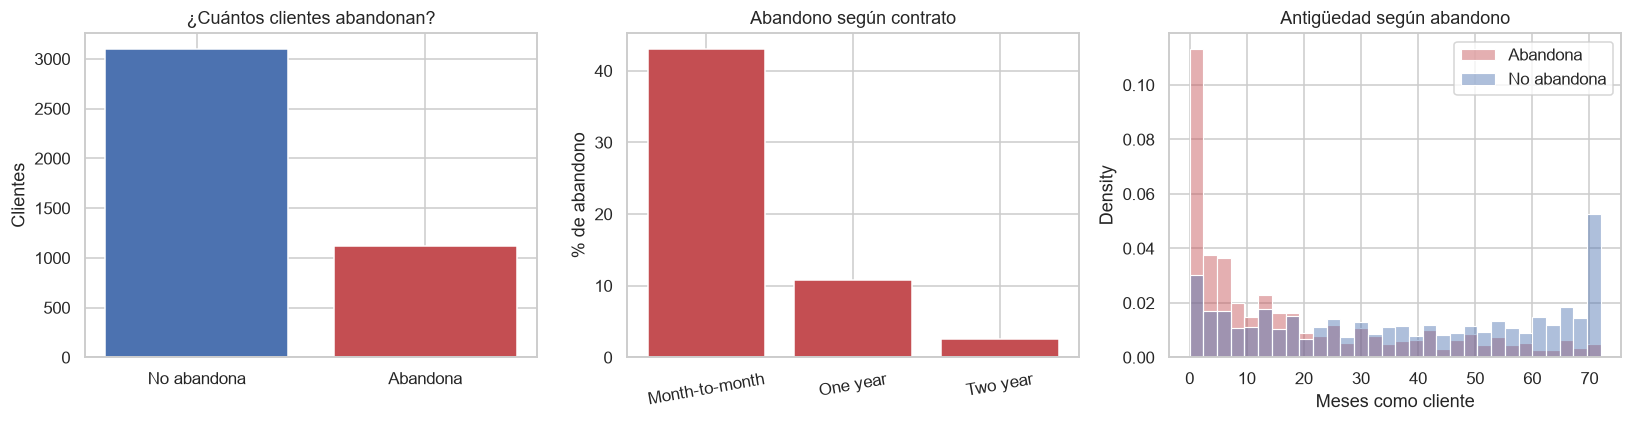

In [7]:
# Figura 1: cuántos abandonan, por contrato y según antigüedad
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Cuántos clientes hay en cada clase
conteo = train["Churn"].map({0: "No abandona", 1: "Abandona"}).value_counts()
axes[0].bar(conteo.index, conteo.values, color=["#4C72B0", "#C44E52"])
axes[0].set_title("¿Cuántos clientes abandonan?")
axes[0].set_ylabel("Clientes")

# Tasa de abandono según el tipo de contrato
tasa_contrato = tasa_por("Contract")
axes[1].bar(tasa_contrato.index, tasa_contrato["tasa"], color="#C44E52")
axes[1].set_title("Abandono según contrato")
axes[1].set_ylabel("% de abandono")
axes[1].tick_params(axis="x", rotation=10)

# Distribución de la antigüedad en cada grupo
sns.histplot(
    data=train,
    x="tenure",
    hue="Churn",
    bins=30,
    stat="density",
    common_norm=False,
    palette={0: "#4C72B0", 1: "#C44E52"},
    alpha=0.45,
    ax=axes[2],
)
axes[2].set_title("Antigüedad según abandono")
axes[2].set_xlabel("Meses como cliente")
axes[2].legend(title="", labels=["Abandona", "No abandona"])

fig.tight_layout()
plt.show()

In [8]:
# 7. Preparar las variables
# Los modelos no entienden texto ("DSL", "Two year"...), así que:
# - variables numéricas: rellenamos huecos y las ponemos en la misma escala
# - variables de texto: las convertimos en columnas de 0 y 1 (one-hot)
# - TotalCharges vacío: lo rellenamos con 0 (cliente nuevo sin facturación)
NUMERICAS = ["tenure", "MonthlyCharges"]
FACTURACION = ["TotalCharges"]
CATEGORICAS = [c for c in X_train.columns if c not in NUMERICAS + FACTURACION]

preprocesador = ColumnTransformer(
    [
        (
            "numericas",
            Pipeline(
                [
                    ("rellenar", SimpleImputer(strategy="median")),
                    ("escalar", StandardScaler()),
                ]
            ),
            NUMERICAS,
        ),
        (
            "facturacion",
            Pipeline(
                [
                    ("rellenar", SimpleImputer(strategy="constant", fill_value=0)),
                    ("escalar", StandardScaler()),
                ]
            ),
            FACTURACION,
        ),
        (
            "categoricas",
            Pipeline(
                [
                    ("rellenar", SimpleImputer(strategy="most_frequent")),
                    ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                ]
            ),
            CATEGORICAS,
        ),
    ]
)

print(f"Variables numéricas   : {NUMERICAS + FACTURACION}")
print(f"Variables categóricas : {len(CATEGORICAS)}")

Variables numéricas   : ['tenure', 'MonthlyCharges', 'TotalCharges']
Variables categóricas : 16


In [9]:
# 8. Referencia: un modelo que siempre dice "no abandona"
# Demuestra por qué la exactitud (accuracy) engaña: acierta ~73 %
# pero no detecta ni un solo abandono.
referencia = DummyClassifier(strategy="most_frequent")
referencia.fit(X_train, y_train)
prediccion = referencia.predict(X_val)

print(f"Accuracy : {accuracy_score(y_val, prediccion):.3f}")
print(f"Recall   : {recall_score(y_val, prediccion, zero_division=0):.3f}")

Accuracy : 0.735
Recall   : 0.000


In [10]:
# 9. Modelo 1: Regresión logística
# Combina las variables con pesos. Es el modelo más fácil de interpretar.
modelo_lr = Pipeline(
    [
        ("preprocesador", preprocesador),
        (
            "modelo",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",  # da más peso a los abandonos
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
modelo_lr.fit(X_train, y_train)
pred_lr = modelo_lr.predict(X_val)
print("Regresión logística entrenada")

Regresión logística entrenada


In [11]:
# 10. Modelo 2: KNN (k vecinos más cercanos)
# Un cliente se clasifica según lo que hacen sus 31 clientes más parecidos.
modelo_knn = Pipeline(
    [
        ("preprocesador", preprocesador),
        ("modelo", KNeighborsClassifier(n_neighbors=31)),
    ]
)
modelo_knn.fit(X_train, y_train)
pred_knn = modelo_knn.predict(X_val)
print("KNN entrenado")

KNN entrenado


In [12]:
# 11. Modelo 3: Árbol de decisión
# Aprende reglas del tipo "si el contrato es mensual y la antigüedad es baja...".
modelo_arbol = Pipeline(
    [
        ("preprocesador", preprocesador),
        (
            "modelo",
            DecisionTreeClassifier(
                max_depth=5,  # evita árboles demasiado grandes
                min_samples_leaf=20,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
modelo_arbol.fit(X_train, y_train)
pred_arbol = modelo_arbol.predict(X_val)
print("Árbol de decisión entrenado")

Árbol de decisión entrenado


In [13]:
# 12. Modelo 4: Random Forest
# Combina 300 árboles distintos y promedia sus respuestas.
modelo_rf = Pipeline(
    [
        ("preprocesador", preprocesador),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=8,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)
modelo_rf.fit(X_train, y_train)
pred_rf = modelo_rf.predict(X_val)
print("Random Forest entrenado")

Random Forest entrenado


In [14]:
# 13. Modelo 5: XGBoost
# Construye árboles uno tras otro, corrigiendo los errores del anterior.
modelo_xgb = Pipeline(
    [
        ("preprocesador", preprocesador),
        (
            "modelo",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=3,
                scale_pos_weight=float((y_train == 0).sum() / (y_train == 1).sum()),
                eval_metric="logloss",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)
modelo_xgb.fit(X_train, y_train)
pred_xgb = modelo_xgb.predict(X_val)
print("XGBoost entrenado")

XGBoost entrenado


In [15]:
# 14. Comparar los cinco modelos en validación
# - Recall:    de los que abandonan, ¿cuántos detectamos?
# - Precision: de los que alertamos, ¿cuántos abandonan de verdad?
# - F1:        equilibrio entre recall y precision.
# - Accuracy:  se muestra solo como referencia.
predicciones_val = {
    "Regresión logística": pred_lr,
    "KNN": pred_knn,
    "Árbol de decisión": pred_arbol,
    "Random Forest": pred_rf,
    "XGBoost": pred_xgb,
}

filas = []
for nombre, prediccion in predicciones_val.items():
    filas.append(
        {
            "Modelo": nombre,
            "Recall": recall_score(y_val, prediccion),
            "Precision": precision_score(y_val, prediccion),
            "F1": f1_score(y_val, prediccion),
            "Accuracy": accuracy_score(y_val, prediccion),
        }
    )

tabla_validacion = pd.DataFrame(filas).set_index("Modelo").sort_values("F1", ascending=False)
tabla_validacion.round(3)

,Recall,Precision,F1,Accuracy
Modelo,,,,
Random Forest,0.781,0.523,0.627,0.753
Regresión logística,0.789,0.517,0.624,0.748
XGBoost,0.775,0.503,0.611,0.737
Árbol de decisión,0.799,0.493,0.610,0.729
KNN,0.561,0.621,0.590,0.793


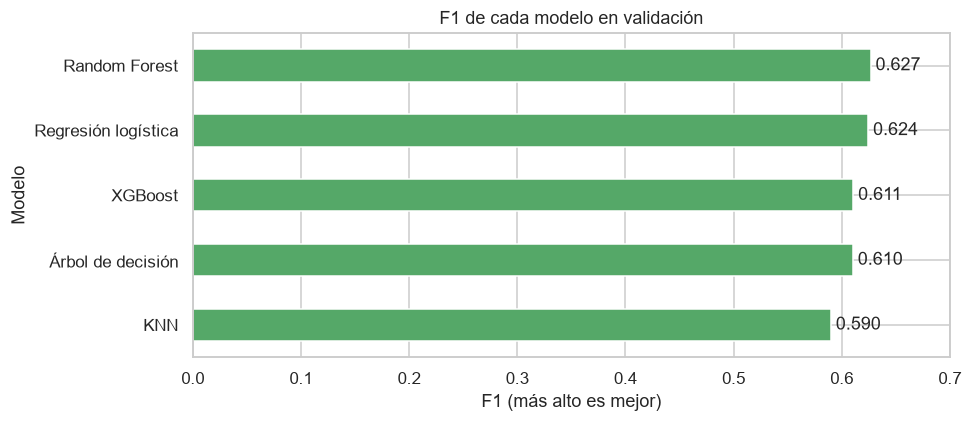

In [16]:
# Figura 2: comparación visual del F1 en validación
fig, ax = plt.subplots(figsize=(9, 4))
tabla_validacion["F1"].sort_values().plot.barh(ax=ax, color="#55A868")
ax.set_title("F1 de cada modelo en validación")
ax.set_xlabel("F1 (más alto es mejor)")
ax.set_xlim(0, 0.7)
for i, valor in enumerate(tabla_validacion["F1"].sort_values()):
    ax.text(valor, i, f" {valor:.3f}", va="center")
fig.tight_layout()
plt.show()

In [17]:
# 15. Elegir el modelo con mayor F1 en validación
# Esta decisión se toma SIN mirar el conjunto de prueba.
nombre_elegido = tabla_validacion.index[0]
print(f"Modelo elegido: {nombre_elegido}")
print(f"F1 en validación: {tabla_validacion.loc[nombre_elegido, 'F1']:.3f}")

Modelo elegido: Random Forest
F1 en validación: 0.627


In [18]:
# 16. Evaluación final sobre el conjunto de prueba
# Se usa el modelo ya elegido. No se cambia nada después de ver este resultado.
modelos = {
    "Regresión logística": modelo_lr,
    "KNN": modelo_knn,
    "Árbol de decisión": modelo_arbol,
    "Random Forest": modelo_rf,
    "XGBoost": modelo_xgb,
}

modelo_final = modelos[nombre_elegido]
pred_final = modelo_final.predict(X_test)

print(f"Modelo: {nombre_elegido}\n")
print(f"Recall    : {recall_score(y_test, pred_final):.3f}")
print(f"Precision : {precision_score(y_test, pred_final):.3f}")
print(f"F1        : {f1_score(y_test, pred_final):.3f}")
print(f"Accuracy  : {accuracy_score(y_test, pred_final):.3f}")

Modelo: Random Forest

Recall    : 0.778
Precision : 0.522
F1        : 0.624
Accuracy  : 0.752


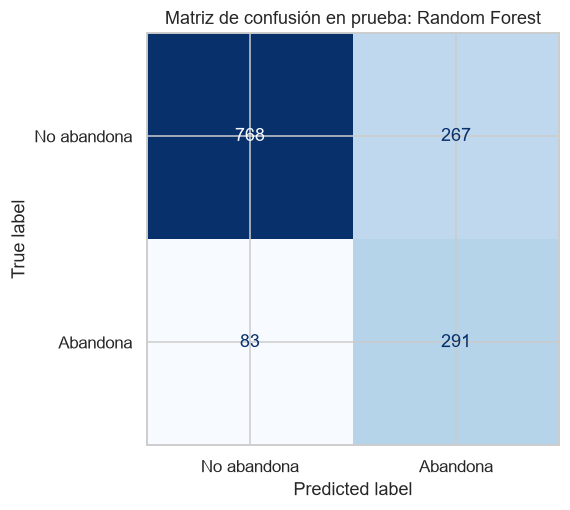

In [19]:
# Figura 3: matriz de confusión del modelo elegido
ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_final,
    display_labels=["No abandona", "Abandona"],
    cmap="Blues",
    colorbar=False,
)
plt.title(f"Matriz de confusión en prueba: {nombre_elegido}")
plt.tight_layout()
plt.show()

In [20]:
# 17. Resumen final
resumen = tabla_validacion.copy()
resumen["Elegido"] = resumen.index == nombre_elegido
print(f"Modelo elegido por F1 de validación: {nombre_elegido}")
print(f"F1 en prueba de ese modelo: {f1_score(y_test, pred_final):.3f}")
resumen.round(3)

Modelo elegido por F1 de validación: Random Forest
F1 en prueba de ese modelo: 0.624


,Recall,Precision,F1,Accuracy,Elegido
Modelo,,,,,
Random Forest,0.781,0.523,0.627,0.753,True
Regresión logística,0.789,0.517,0.624,0.748,False
XGBoost,0.775,0.503,0.611,0.737,False
Árbol de decisión,0.799,0.493,0.610,0.729,False
KNN,0.561,0.621,0.590,0.793,False
